*Author:*  
Manuel Eugenio Morocho Cayamcela, PhD

Edited by:
Darío Julián Echeverría Castro

# Prediction with a Keras Neural Network

Build, monitor, and evaluate a binary classifier using a categorical dataset.

## Learning goals

- Prepare features for modeling.
- Train a small Keras network for binary classification.
- Inspect learning curves with TensorBoard and use early stopping.

python -c "import tensorflow as tf; print(tf.__version__)"## Contents

## 1. Load and inspect the data

Load the dataset into a DataFrame and inspect the first rows.

In [ ]:
#%pip install -q pandas matplotlib seaborn scikit-learn tensorflow==2.19.0
#%pip install tensorboard
#%pip install --force-reinstall --no-deps matplotlib

  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.11.2
Note: you may need to restart the kernel to use updated packages.


error: uninstall-no-record-file

× Cannot uninstall matplotlib 3.11.2
╰─> The package's contents are unknown: no RECORD file was found for matplotlib.

hint: You might be able to recover from this via: pip install --ignore-installed --no-deps matplotlib==3.11.2


In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import tensorflow as tf

#SEED = 42
#tf.keras.utils.set_random_seed(SEED)

Conjunto de datos de cobertura vegetal, desde sklearn. (Fuente adicional: https://archive.ics.uci.edu/dataset/31/covertype). La variable objetivo se define en las siguientes clases:


|Valor original	|Cobertura
|---------------|----------
|1	|Spruce/Fir (picea/abeto)
|2	|Lodgepole Pine (pino contorta)
|3	|Ponderosa Pine (pino ponderosa)
|4	|Cottonwood/Willow (álamo/sauce)
|5	|Aspen (álamo temblón)
|6	|Douglas-fir (abeto de Douglas)
|7	|Krummholz (vegetación arbustiva de alta montaña)

Para el análisis, se compararán solo 2 clases primeras. Spruce/Fir y Lodgepole Pine son ecológicamente parecidas y se confunden entre sí

In [2]:
from sklearn.datasets import fetch_covtype

covtype = fetch_covtype(as_frame = True)
df = covtype.frame

print(df.shape)
print(df["Cover_Type"].value_counts(normalize=True).sort_index())

(581012, 55)
Cover_Type
1    0.364605
2    0.487599
3    0.061537
4    0.004728
5    0.016339
6    0.029891
7    0.035300
Name: proportion, dtype: float64


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 581012 entries, 0 to 581011
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           581012 non-null  float64
 1   Aspect                              581012 non-null  float64
 2   Slope                               581012 non-null  float64
 3   Horizontal_Distance_To_Hydrology    581012 non-null  float64
 4   Vertical_Distance_To_Hydrology      581012 non-null  float64
 5   Horizontal_Distance_To_Roadways     581012 non-null  float64
 6   Hillshade_9am                       581012 non-null  float64
 7   Hillshade_Noon                      581012 non-null  float64
 8   Hillshade_3pm                       581012 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  581012 non-null  float64
 10  Wilderness_Area_0                   581012 non-null  float64
 11  Wilderness_Area_1         

In [4]:
# Conjunto de datos con las clases 1 y 2
cov_df = df[df["Cover_Type"].isin([1, 2])].copy()
cov_df.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
5,2579.0,132.0,6.0,300.0,-15.0,67.0,230.0,237.0,140.0,6031.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
11,2886.0,151.0,11.0,371.0,26.0,5253.0,234.0,240.0,136.0,4051.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
12,2742.0,134.0,22.0,150.0,69.0,3215.0,248.0,224.0,92.0,6091.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


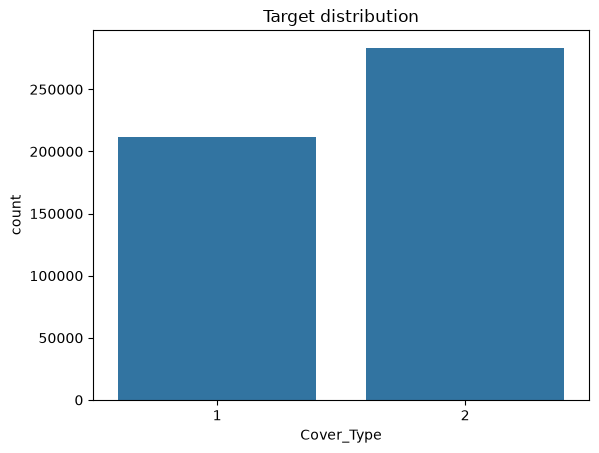

In [5]:
sns.countplot(data=cov_df, x="Cover_Type");
plt.title("Target distribution");

**Features:**

|Name | Data Type | Measurement | Description
|-----|-----------|-------------|-------------
|Elevation | quantitative |meters | Elevation in meters
|Aspect | quantitative | azimuth | Aspect in degrees azimuth
|Slope | quantitative | degrees | Slope in degrees
|Horizontal_Distance_To_Hydrology | quantitative | meters | Horz Dist to nearest surface water features
|Vertical_Distance_To_Hydrology | quantitative | meters | Vert Dist to nearest surface water features
|Horizontal_Distance_To_Roadways | quantitative | meters | Horz Dist to nearest roadway
|Hillshade_9am | quantitative | 0 to 255 index | Hillshade index at 9am, summer solstice
|Hillshade_Noon | quantitative | 0 to 255 index | Hillshade index at noon, summer soltice
|Hillshade_3pm | quantitative | 0 to 255 index | Hillshade index at 3pm, summer solstice
|Horizontal_Distance_To_Fire_Points | quantitative | meters | Horz Dist to nearest wildfire ignition points
|Wilderness_Area (4 binary columns) | qualitative | 0 (absence) or 1 (presence) | Wilderness area designation
|Soil_Type (40 binary columns) | qualitative | 0 (absence) or 1 (presence) | Soil Type designation
|Cover_Type (7 types) | integer | 1 to 7 | Forest Cover Type designation

## 2. Prepare the data

Inspect data types and missing values.

In [6]:
cov_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 495141 entries, 2 to 576886
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           495141 non-null  float64
 1   Aspect                              495141 non-null  float64
 2   Slope                               495141 non-null  float64
 3   Horizontal_Distance_To_Hydrology    495141 non-null  float64
 4   Vertical_Distance_To_Hydrology      495141 non-null  float64
 5   Horizontal_Distance_To_Roadways     495141 non-null  float64
 6   Hillshade_9am                       495141 non-null  float64
 7   Hillshade_Noon                      495141 non-null  float64
 8   Hillshade_3pm                       495141 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  495141 non-null  float64
 10  Wilderness_Area_0                   495141 non-null  float64
 11  Wilderness_Area_1              

#### Outliers

##### Plot the value range of each column

A boxplot summarizes each feature's distribution through its median, quartiles, range, and potential outliers, only for numerical variables.

['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points']


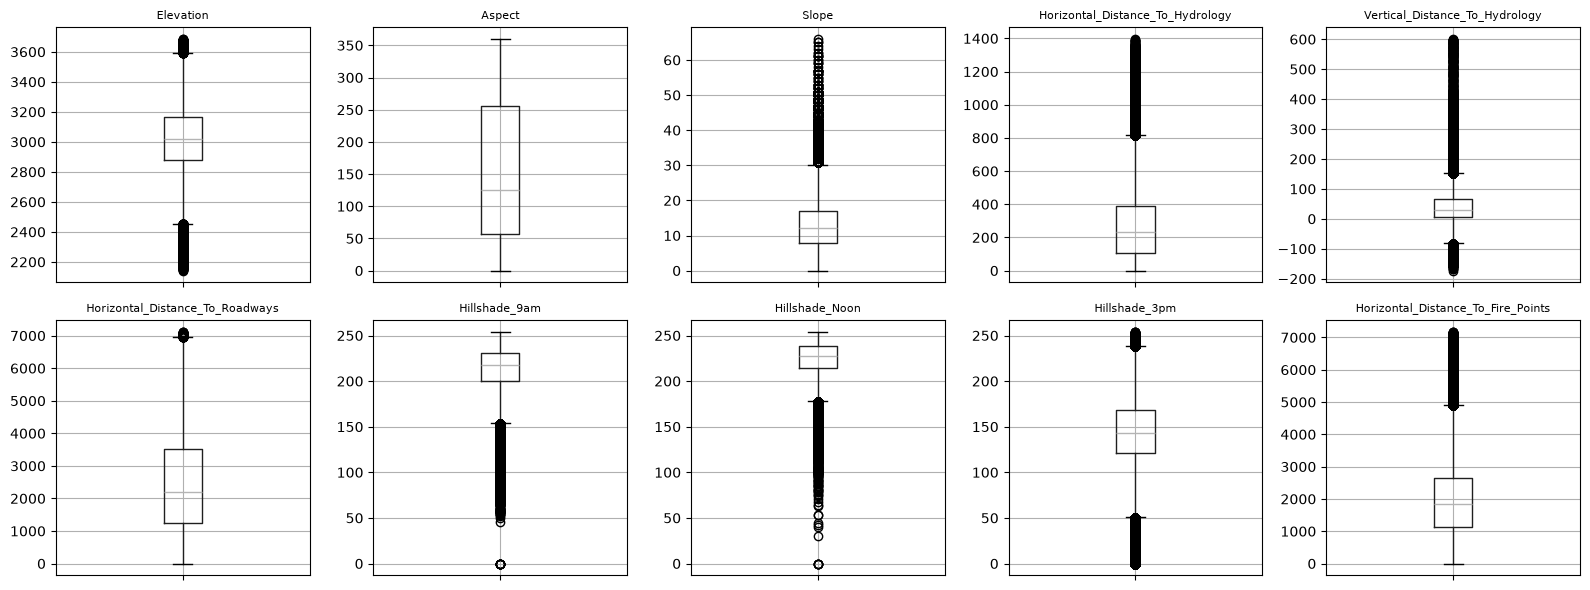

In [7]:
# Variables no dummy: se excluyen las columnas con solo valores 0/1 y la variable objetivo
dummy_cols = [c for c in cov_df.columns if set(cov_df[c].unique()) <= {0, 1}]
num_cols = [c for c in cov_df.columns if c not in dummy_cols + ["Cover_Type"]]
print(num_cols)

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.flat, num_cols):
    cov_df.boxplot(column=col, ax=ax)
    ax.set_title(col, fontsize=8)
    ax.set_xticklabels([])
plt.tight_layout()
plt.show()

This dataset doesn't require cleaning.

#### Plot feature correlations

Use a correlation heatmap to identify linear relationships. Correlation is not causation; weak individual correlations can still be useful in combination.

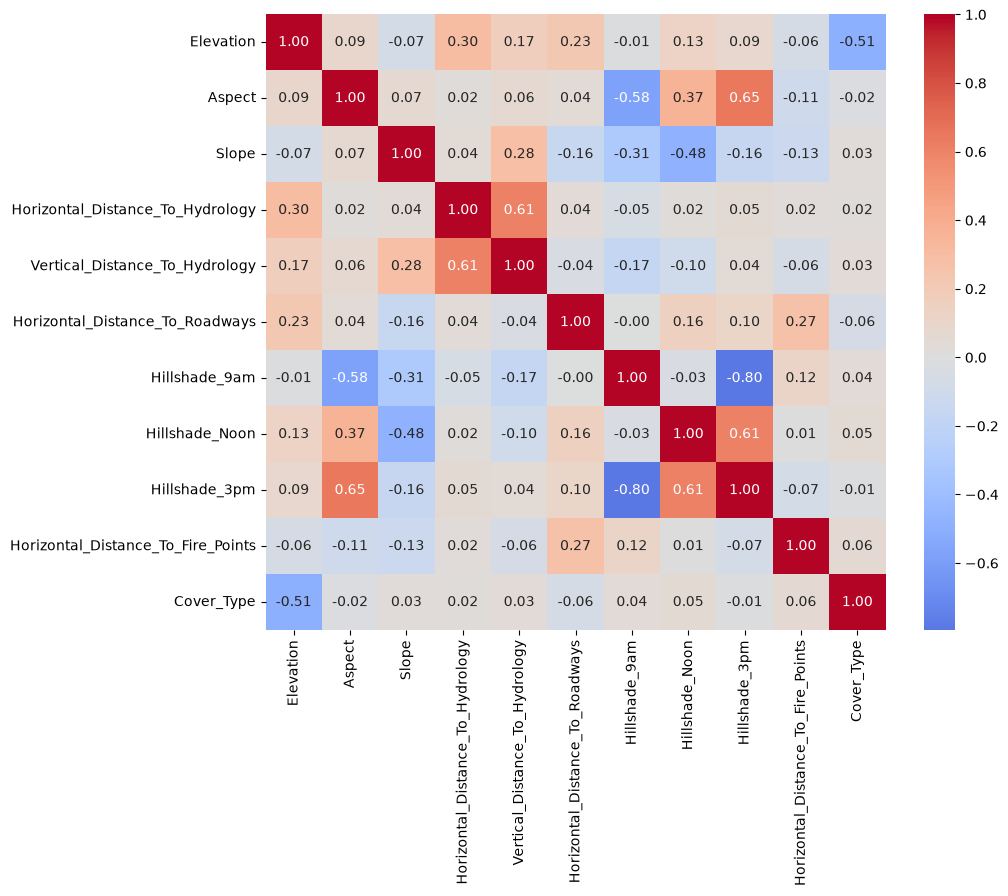

In [8]:
# Plot the correlation matrix
cols_corr = list(num_cols) + ["Cover_Type"]

plt.figure(figsize=(10, 8))
sns.heatmap(cov_df[cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

Correlation analysis describes linear relationships among features and the target. Strong feature-to-feature correlations may indicate redundancy, while weak individual correlations can still help a nonlinear model.

Remember that correlation does not imply causation.

In [9]:
cov_df["Cover_Type"] = cov_df["Cover_Type"] - 1

# Submuestreo estratificado sobre la nueva variable objetivo para reducir el tamaño del conjunto de datos 
# y acelerar el entrenamiento
df_samp = cov_df.groupby("Cover_Type", group_keys=False).sample(frac=0.1, random_state=42)

# División de los datos en variables predictoras y variable objetivo
X = df_samp.drop(columns=["Cover_Type"])
y = df_samp["Cover_Type"]

In [10]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49514 entries, 502947 to 307543
Data columns (total 54 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Elevation                           49514 non-null  float64
 1   Aspect                              49514 non-null  float64
 2   Slope                               49514 non-null  float64
 3   Horizontal_Distance_To_Hydrology    49514 non-null  float64
 4   Vertical_Distance_To_Hydrology      49514 non-null  float64
 5   Horizontal_Distance_To_Roadways     49514 non-null  float64
 6   Hillshade_9am                       49514 non-null  float64
 7   Hillshade_Noon                      49514 non-null  float64
 8   Hillshade_3pm                       49514 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  49514 non-null  float64
 10  Wilderness_Area_0                   49514 non-null  float64
 11  Wilderness_Area_1                   4951

#### Split the data into training and test sets

Use 70% of the data for training and reserve 30% for the final test. Stratification preserves the target class ratio in both sets.

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
)

## 3. Build and train the neural network

A compact network with ReLU hidden layers and a sigmoid output predicts the probability of trees coverage:
- 0 - Spruce/Fir (picea/abeto), y
- 1 - Lodgepole Pine (pino contorta).

TensorFlow and scikit-learn are installed in the setup cell above. TensorFlow provides the Keras API used to build the neural network.

#### Define a simple neural network

Import `Sequential` to stack layers and `Dense` to create fully connected layers.

In [13]:
# Import the modules used to build the model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

The network has two hidden ReLU layers with 100 and 100 units. A single sigmoid output returns the estimated probability of coverage belonging to pino contorta.

In [14]:
# To define the input shape of the model, we need to know the number of features in the training data. The shape of X_train is (number of samples, number of features). By accessing X_train.shape[1], we get the number of features, which will be used as the input dimension for the first layer of the neural network.
X_train.shape[1] 

54

In [16]:
model = Sequential([
    tf.keras.Input(shape=(X_train.shape[1],)), # Capa de entrada de 8 neuronas (una por cada característica de entrada)
    Dense(100, activation="relu"), # Capa oculta de 100 neuronas con función de activación ReLU
    Dense(100, activation="relu"), # Capa oculta de 100 neuronas con función de activación ReLU
    Dense(1, activation="sigmoid"), # Capa de salida de 1 neurona con función de activación sigmoide (para clasificación binaria)
])

# Change the output layer from one unit to two:
# Dense(2, activation="softmax")

#### Compile the neural network

Compile with Adam, binary cross-entropy, and accuracy. Binary cross-entropy matches the two possible target classes.

In [17]:
# Compile with Adam, binary cross-entropy, and accuracy
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
# La entropía compara la salida con la entrada y calcula la entropía (el cuadrado de todos los valores de la salida) 
# La entropía es una medida de la incertidumbre o aleatoriedad en un sistema. 
# En el contexto de redes neuronales, la entropía cruzada se utiliza como función de pérdida para problemas de clasificación, 
# donde se compara la distribución de probabilidad predicha por el modelo con la distribución de probabilidad real 
# (etiquetas verdaderas). La entropía cruzada penaliza más fuertemente las predicciones incorrectas, 
# lo que ayuda a mejorar la precisión del modelo durante el entrenamiento.

#### Inspect the neural-network summary

`model.summary()` displays each layer, its output shape, and its trainable parameters.

In [18]:
# Display the model summary
model.summary()
# La matriz se lee: [número de capas] x [número de neuronas por capa] + sesgo. 
# Por ejemplo, la primera capa tiene 12 neuronas y 8 entradas, por lo que el número de 
# parámetros es (8 * 12) + 12 = 108. 
# La segunda capa tiene 8 neuronas y 12 entradas, por lo que el número de 
# parámetros es (12 * 8) + 8 = 104. 
# La tercera capa tiene 1 neurona y 8 entradas, por lo que el número de 
# parámetros es (8 * 1) + 1 = 9. 
# En total, el modelo tiene 221 parámetros entrenables.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 100)            │         5,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,701 (61.33 KB)

 Trainable params: 15,701 (61.33 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Display the model output shape
model.output_shape

(None, 1)

#### Train the neural network

`model.fit()` learns from the training examples. An epoch is one pass through the training set; `batch_size` controls how many examples are processed before each weight update.

#### Train with early stopping to reduce overfitting

In [19]:
log_dir = Path("logs/fit") / datetime.now().strftime("%Y%m%d-%H%M%S")
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20, restore_best_weights=True 
        # el parametro patience indica el número de épocas que se esperará sin mejora antes de detener el entrenamiento
    ),
    tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1), 
    # este paso es opcional para almacenar los puntos de control del modelo para luego visualizarlos con TensorBoard
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)
print(f"TensorBoard logs written to: {log_dir}")

Epoch 1/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5923 - loss: 5.8490 - val_accuracy: 0.6280 - val_loss: 2.4946
Epoch 2/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6462 - loss: 3.0391 - val_accuracy: 0.5870 - val_loss: 5.1617
Epoch 3/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6715 - loss: 2.2484 - val_accuracy: 0.6947 - val_loss: 1.7526
Epoch 4/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6692 - loss: 2.3632 - val_accuracy: 0.6369 - val_loss: 2.3240
Epoch 5/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6935 - loss: 1.5520 - val_accuracy: 0.6780 - val_loss: 1.3019
Epoch 6/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6855 - loss: 1.4727 - val_accuracy: 0.6144 - val_loss: 1.9197
Epoch 7/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.6898 - loss: 1.3573 - val_accuracy: 0.5788 - val_loss: 5.6686
Epoch 8/200
867/867 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7089 - loss: 1.0364 - val_accu

In [20]:
# Para utilizar TensorBoard
import os, sys
from pathlib import Path

scripts_dir = Path(sys.prefix) / "Scripts"
os.environ["PATH"] = str(scripts_dir) + os.pathsep + os.environ["PATH"]
os.environ["TENSORBOARD_BINARY"] = str(scripts_dir / "tensorboard.exe")
print(os.environ["TENSORBOARD_BINARY"], (scripts_dir / "tensorboard.exe").exists())

c:\Users\darth\.conda\envs\env_mcd\Scripts\tensorboard.exe True


In [21]:
%load_ext tensorboard

In [24]:
import tempfile, shutil
from pathlib import Path

# Borra los registros de TensorBoard que quedaron de procesos que ya terminaron
shutil.rmtree(Path(tempfile.gettempdir()) / ".tensorboard-info", ignore_errors=True)


In [ ]:
# Make sure to run this command in the specific folder where the logs are stored. 
# You can also specify a different log directory if you have set it up differently 
# in the code above.
%tensorboard --logdir logs/fit

Reusing TensorBoard on port 6006 (pid 5488), started 0:00:16 ago. (Use '!kill 5488' to kill it.)

## 4. Evaluate the model

Evaluate loss and accuracy on both the training and test sets. Compare the results to check for potential overfitting.

In [27]:
# Evaluate on the training data
scores = model.evaluate(X_train, y_train, verbose=False)
print("Training accuracy: %.2f%%" % (scores[1] * 100))

# Evaluate on the test data
scores = model.evaluate(X_test, y_test, verbose=False)
print("Test accuracy: %.2f%%" % (scores[1] * 100))

Training accuracy: 82.20%
Test accuracy: 81.27%


## 5. Make a prediction

Select one example from the test set. `iloc[9]` returns its tenth row.

In [28]:
# Select a person from the test set for prediction
prueba = X_test.iloc[100]
prueba

Elevation                             2631.0
Aspect                                 323.0
Slope                                   10.0
Horizontal_Distance_To_Hydrology       192.0
Vertical_Distance_To_Hydrology          22.0
Horizontal_Distance_To_Roadways        474.0
Hillshade_9am                          194.0
Hillshade_Noon                         230.0
Hillshade_3pm                          175.0
Horizontal_Distance_To_Fire_Points    1167.0
Wilderness_Area_0                        1.0
Wilderness_Area_1                        0.0
Wilderness_Area_2                        0.0
Wilderness_Area_3                        0.0
Soil_Type_0                              0.0
Soil_Type_1                              0.0
Soil_Type_2                              0.0
Soil_Type_3                              0.0
Soil_Type_4                              0.0
Soil_Type_5                              0.0
Soil_Type_6                              0.0
Soil_Type_7                              0.0
Soil_Type_

Keras expects a two-dimensional input. Reshape the selected row into one sample with eight features before calling `predict()`.

In [29]:
# Predict with the trained model
prediccion = model.predict(prueba.values.reshape(1,54))
prediccion

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


array([[0.9473211]], dtype=float32)

Classify the predicted probability using a 0.5 threshold, then compare that class with the known test label.

In [38]:
# Classify the model prediction
# Spruce/Fir y Lodgepole Pine
if prediccion >= 0.5:
    print('Neural-network prediction: Lodgepole Pine')
else:
    print('Neural-network prediction: Spruce/Fir')
    
# Display the true test label
if y_test.iloc[100] == 1:
    print('Test dataset label: Lodgepole Pine')
else:
    print('Test dataset label: Spruce/Fir')

Neural-network prediction: Lodgepole Pine
Test dataset label: Lodgepole Pine


## 6. Save and reload the model

In [31]:
# Save the model to a file
model.save('modelo_diabetes.keras')

In [32]:
# Load the model from the file
from tensorflow.keras.models import load_model
modelo_cargado = load_model('modelo_diabetes.keras')

In [33]:
# Predict with the reloaded model
prediccion_modelo_cargado = modelo_cargado.predict(prueba.values.reshape(1,54))

# Classify the reloaded-model prediction
if prediccion_modelo_cargado >= 0.5:
    print('Reloaded-model prediction: Lodgepole Pine')
else:
    print('Reloaded-model prediction: Spruce/Fir')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Reloaded-model prediction: Lodgepole Pine


## Activity: Optimize the neural-network architecture

### Goal
Work in groups to improve the classifier through hyperparameter search.

### Instructions

1. Form a group of 2 or work individually.
2. Search for a new dataset
3. Build a neural network and use `keras-tuner`, or `optuna` to search for the best hyperparameters.
4. Evaluate the best model and report the results.

In [ ]:
#%pip install optuna

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 2.4/2.4 MB 32.3 MB/s  0:00:00

   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
   ---------------------------------------- 0/5 [sqlalchemy]
  

In [34]:
import optuna
from sklearn.preprocessing import StandardScaler

# Validación separada del entrenamiento: Optuna optimiza sobre ella y el test queda intacto
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

# Escalar solo las variables continuas; las dummies se dejan como 0/1
scaler = StandardScaler().fit(X_tr[num_cols])

def escalar(df):
    df = df.copy()
    df[num_cols] = scaler.transform(df[num_cols])
    return df.astype("float32")

X_tr_s, X_val_s = escalar(X_tr), escalar(X_val)
X_train_s, X_test_s = escalar(X_train), escalar(X_test)

In [35]:
from tensorflow.keras.layers import Dropout

def crear_modelo(trial, n_features):
    n_capas = trial.suggest_int("n_capas", 1, 4)
    dropout = trial.suggest_float("dropout", 0.0, 0.5)
    activacion = trial.suggest_categorical("activacion", ["relu", "elu"])
    lr = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)
    optim = trial.suggest_categorical("optimizador", ["adam", "rmsprop"])

    capas = [tf.keras.Input(shape=(n_features,))]
    for i in range(n_capas):
        unidades = trial.suggest_int(f"unidades_{i}", 16, 256, log=True)
        capas.append(Dense(unidades, activation=activacion))
        if dropout > 0:
            capas.append(Dropout(dropout))
    capas.append(Dense(1, activation="sigmoid"))
    modelo = Sequential(capas)

    opt = (tf.keras.optimizers.Adam(learning_rate=lr) if optim == "adam"
           else tf.keras.optimizers.RMSprop(learning_rate=lr))
    modelo.compile(optimizer=opt, loss="binary_crossentropy", metrics=["accuracy"])
    return modelo


class PodaOptuna(tf.keras.callbacks.Callback):
    """Informa a Optuna el val_accuracy de cada época y corta los trials poco prometedores."""
    def __init__(self, trial):
        super().__init__()
        self.trial = trial
    def on_epoch_end(self, epoch, logs=None):
        self.trial.report(logs["val_accuracy"], epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    tf.keras.backend.clear_session()
    modelo = crear_modelo(trial, X_tr_s.shape[1])
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128, 256])

    modelo.fit(
        X_tr_s, y_tr,
        validation_data=(X_val_s, y_val),
        epochs=50,
        batch_size=batch_size,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            PodaOptuna(trial),
        ],
        verbose=0,
    )
    _, val_acc = modelo.evaluate(X_val_s, y_val, verbose=0)
    return val_acc


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5),
)
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("Mejor val_accuracy:", round(study.best_value, 4))
print("Mejores hiperparámetros:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")


[I 2026-11-12 22:40:52,531] A new study created in memory with name: no-name-70c84672-f658-49a7-aada-a8cb4df9dd7b


  0%|          | 0/30 [00:00<?, ?it/s]


[I 2026-11-12 22:41:13,651] Trial 0 finished with value: 0.8157818913459778 and parameters: {'n_capas': 2, 'dropout': 0.4753571532049581, 'activacion': 'relu', 'learning_rate': 0.0002051338263087451, 'optimizador': 'adam', 'unidades_0': 176, 'unidades_1': 84, 'batch_size': 128}. Best is trial 0 with value: 0.8157818913459778.
[I 2026-11-12 22:41:24,839] Trial 1 finished with value: 0.7928447723388672 and parameters: {'n_capas': 1, 'dropout': 0.09091248360355031, 'activacion': 'elu', 'learning_rate': 0.0011207606211860567, 'optimizador': 'adam', 'unidades_0': 86, 'batch_size': 256}. Best is trial 0 with value: 0.8157818913459778.
[I 2026-11-12 22:41:59,372] Trial 2 finished with value: 0.7968840003013611 and parameters: {'n_capas': 4, 'dropout': 0.09983689107917987, 'activacion': 'elu', 'learning_rate': 0.0001238513729886094, 'optimizador': 'adam', 'unidades_0': 19, 'unidades_1': 222, 'unidades_2': 233, 'unidades_3': 150, 'batch_size': 128}. Best is trial 0 with value: 0.81578189134597

In [36]:
tf.keras.backend.clear_session()
mejor_trial = study.best_trial
mejor_modelo = crear_modelo(mejor_trial, X_train_s.shape[1])

log_dir_opt = Path("logs/fit") / ("optuna_" + datetime.now().strftime("%Y%m%d-%H%M%S"))
history_opt = mejor_modelo.fit(
    X_train_s, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=mejor_trial.params["batch_size"],
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
        tf.keras.callbacks.TensorBoard(log_dir=log_dir_opt),
    ],
    verbose=0,
)

_, acc_train_opt = mejor_modelo.evaluate(X_train_s, y_train, verbose=0)
_, acc_test_opt = mejor_modelo.evaluate(X_test_s, y_test, verbose=0)
_, acc_train_base = model.evaluate(X_train, y_train, verbose=0)
_, acc_test_base = model.evaluate(X_test, y_test, verbose=0)

print(pd.DataFrame({
    "Base": [acc_train_base, acc_test_base],
    "Optuna": [acc_train_opt, acc_test_opt],
}, index=["Train accuracy", "Test accuracy"]).round(4))


                  Base  Optuna
Train accuracy  0.8220  0.9448
Test accuracy   0.8127  0.9046


In [ ]:
#%pip install plotly

In [37]:
optuna.visualization.plot_optimization_history(study).show()
optuna.visualization.plot_param_importances(study).show()

a. Which hyperparameter search method did you use?
- *Optuna*

b. Which parameters did you search?
- *n_capas:* Capas ocultas, de 1 a 4
- *dropout:* Tasa que varía de 0 a 0.5
- *activacion:* Funciones de activación ReLu y ELu
- *learning_rate:* Tasa de aprendizaje de 0.0001 a 0.01
- *optimizador:* Algoritmo de optimización adam o rmsprop
- *unidades:* Neuronas por capa (máximo 4)
- *batch_size:* Tamaño del lote de muestra, de 32 (grandes), 64, 128 y 256 (pequeños)

c. How do the optimized network metrics compare with the baseline network?
- *Son mejores claramente*, para la métrica revisada de precisión, pasan de 82.2 % a 
94.48 % en el entrenamiento, y de 81.27 % a 90.46 %S en el grupo de prueba.

d. What else would you try to improve the metrics or reduce overfitting?
- Probar con el *escalado* y no escalado de datos para analizar si aporta o no al modelado.
También se puede utilizar validación cruzada. El modelo optimizado parace estar sobreajustado porque tiene aproximadamente 4 pp de diferencia, por lo que se puede aumentar el número de datos.